# 02 Credit-market analysis: issuance, concentration, new-issue pricing, macro conditions
SEC-registered issuance only (A); SIFMA and bfinance/J.P. Morgan figures are published statistics (B).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
T = ROOT / 'outputs' / 'tables'; F = ROOT / 'outputs' / 'figures'
def show_md(name): display(Markdown((T / f'{name}.md').read_text()))
def show_fig(name): display(Image(filename=str(F / f'{name}.png'), width=900))

In [2]:
tr = pd.read_csv(ROOT/'data/curated/bond_issuance_tranches_with_analytics.csv', parse_dates=['filing_date'])
tr.groupby(['issue_year','ticker']).principal_usd.sum().div(1e9).unstack().round(2)

ticker,AMZN,GOOGL,META,MSFT,ORCL
issue_year,,,,,
2020,10.00,10.00,NaN,NaN,20.00
2021,18.50,NaN,NaN,NaN,15.00
2022,21.00,NaN,NaN,NaN,7.00
2023,NaN,NaN,8.50,NaN,5.25
2024,NaN,NaN,10.50,NaN,6.25
2025,15.00,37.58,30.00,NaN,25.75
2026,94.39,79.68,50.04,25.0,35.00


**Table S1. SEC-registered bond issuance by issuer and year**

| ticker | issue_year | gross_all_ccy_usd_bn | gross_usd_denominated_bn | n_tranches | n_deals | pw_avg_tenor_y | median_tenor_y | share_principal_tenor_over_25y |
|---|---|---|---|---|---|---|---|---|
| AMZN | 2020 | 10.00 | 10.00 | 6.00 | 1.00 | 19.30 | 8.50 | 0.450 |
| AMZN | 2021 | 18.50 | 18.50 | 8.00 | 1.00 | 14.95 | 8.50 | 0.270 |
| AMZN | 2022 | 21.00 | 21.00 | 12.00 | 2.00 | 10.82 | 6.00 | 0.179 |
| AMZN | 2025 | 15.00 | 15.00 | 6.00 | 1.00 | 15.80 | 9.00 | 0.333 |
| AMZN | 2026 | 94.39 | 62.00 | 36.00 | 5.00 | 14.40 | 7.00 | 0.239 |
| GOOGL | 2020 | 10.00 | 10.00 | 6.00 | 1.00 | 21.45 | 15.00 | 0.450 |
| GOOGL | 2025 | 37.58 | 22.50 | 23.00 | 4.00 | 18.75 | 10.00 | 0.335 |
| GOOGL | 2026 | 79.68 | 45.00 | 46.00 | 7.00 | 15.56 | 8.50 | 0.245 |
| META | 2023 | 8.50 | 8.50 | 5.00 | 1.00 | 20.82 | 10.00 | 0.500 |
| META | 2024 | 10.50 | 10.50 | 5.00 | 1.00 | 23.29 | 10.00 | 0.571 |
| META | 2025 | 30.00 | 30.00 | 6.00 | 1.00 | 19.27 | 15.00 | 0.367 |
| META | 2026 | 50.04 | 40.00 | 17.00 | 3.00 | 17.16 | 10.00 | 0.288 |
| MSFT | 2026 | 25.00 | 25.00 | 10.00 | 1.00 | 13.30 | 6.00 | 0.240 |
| ORCL | 2020 | 20.00 | 20.00 | 6.00 | 1.00 | 20.04 | 15.00 | 0.400 |
| ORCL | 2021 | 15.00 | 15.00 | 6.00 | 1.00 | 17.52 | 15.00 | 0.317 |
| ORCL | 2022 | 7.00 | 7.00 | 4.00 | 1.00 | 15.61 | 8.50 | 0.357 |
| ORCL | 2023 | 5.25 | 5.25 | 4.00 | 1.00 | 17.43 | 8.50 | 0.429 |
| ORCL | 2024 | 6.25 | 6.25 | 4.00 | 1.00 | 20.40 | 20.00 | 0.480 |
| ORCL | 2025 | 25.75 | 25.75 | 12.00 | 2.00 | 16.92 | 10.00 | 0.320 |
| ORCL | 2026 | 35.00 | 35.00 | 13.00 | 2.00 | 14.06 | 7.00 | 0.221 |

Source: SEC EDGAR final prospectus supplements. USD-equivalent at FRED H.10 FX on/before filing date. Tenor approx. = maturity year − issue year. Gross issuance, not net or outstanding.


**Table S2. Five-issuer USD registered issuance vs SIFMA market issuance**

| period | five_issuer_usd_registered_bn | denominator_bn | denominator | share_of_denominator | sifma_stat_id |
|---|---|---|---|---|---|
| FY2023 | 13.75 | 1,503.5 | SIFMA total US corporate issuance (all types) | 0.009 | sifma_corp_iss_2023 |
| FY2024 | 16.75 | 1,968.9 | SIFMA total US corporate issuance (all types) | 0.009 | sifma_corp_iss_2024 |
| FY2025 | 93.25 | 2,216.3 | SIFMA total US corporate issuance (all types) | 0.042 | sifma_corp_iss_2025 |
| 2026 Jan-Sep | 157.0 | 2,195.1 | SIFMA total US corporate issuance (all types) | 0.072 | sifma_corp_iss_2026q1q3 |
| 2026 Jan-Oct | 157.0 | 2,342.6 | SIFMA total US corporate issuance (all types) | 0.067 | sifma_corp_iss_2026ytd_oct |
| 3Q26 (IG-only denominator) | 50.00 | 482.7 | SIFMA 3Q26 total × SIFMA 3Q26 IG share | 0.104 | sifma_corp_iss_3q26 × sifma_corp_ig_share_3q26 |

Numerator: five issuers' USD-denominated SEC-registered issuance by final prospectus date. Denominator: SIFMA (B, published). IG-only denominator available only for 3Q26 (SIFMA IG share 74.3%).


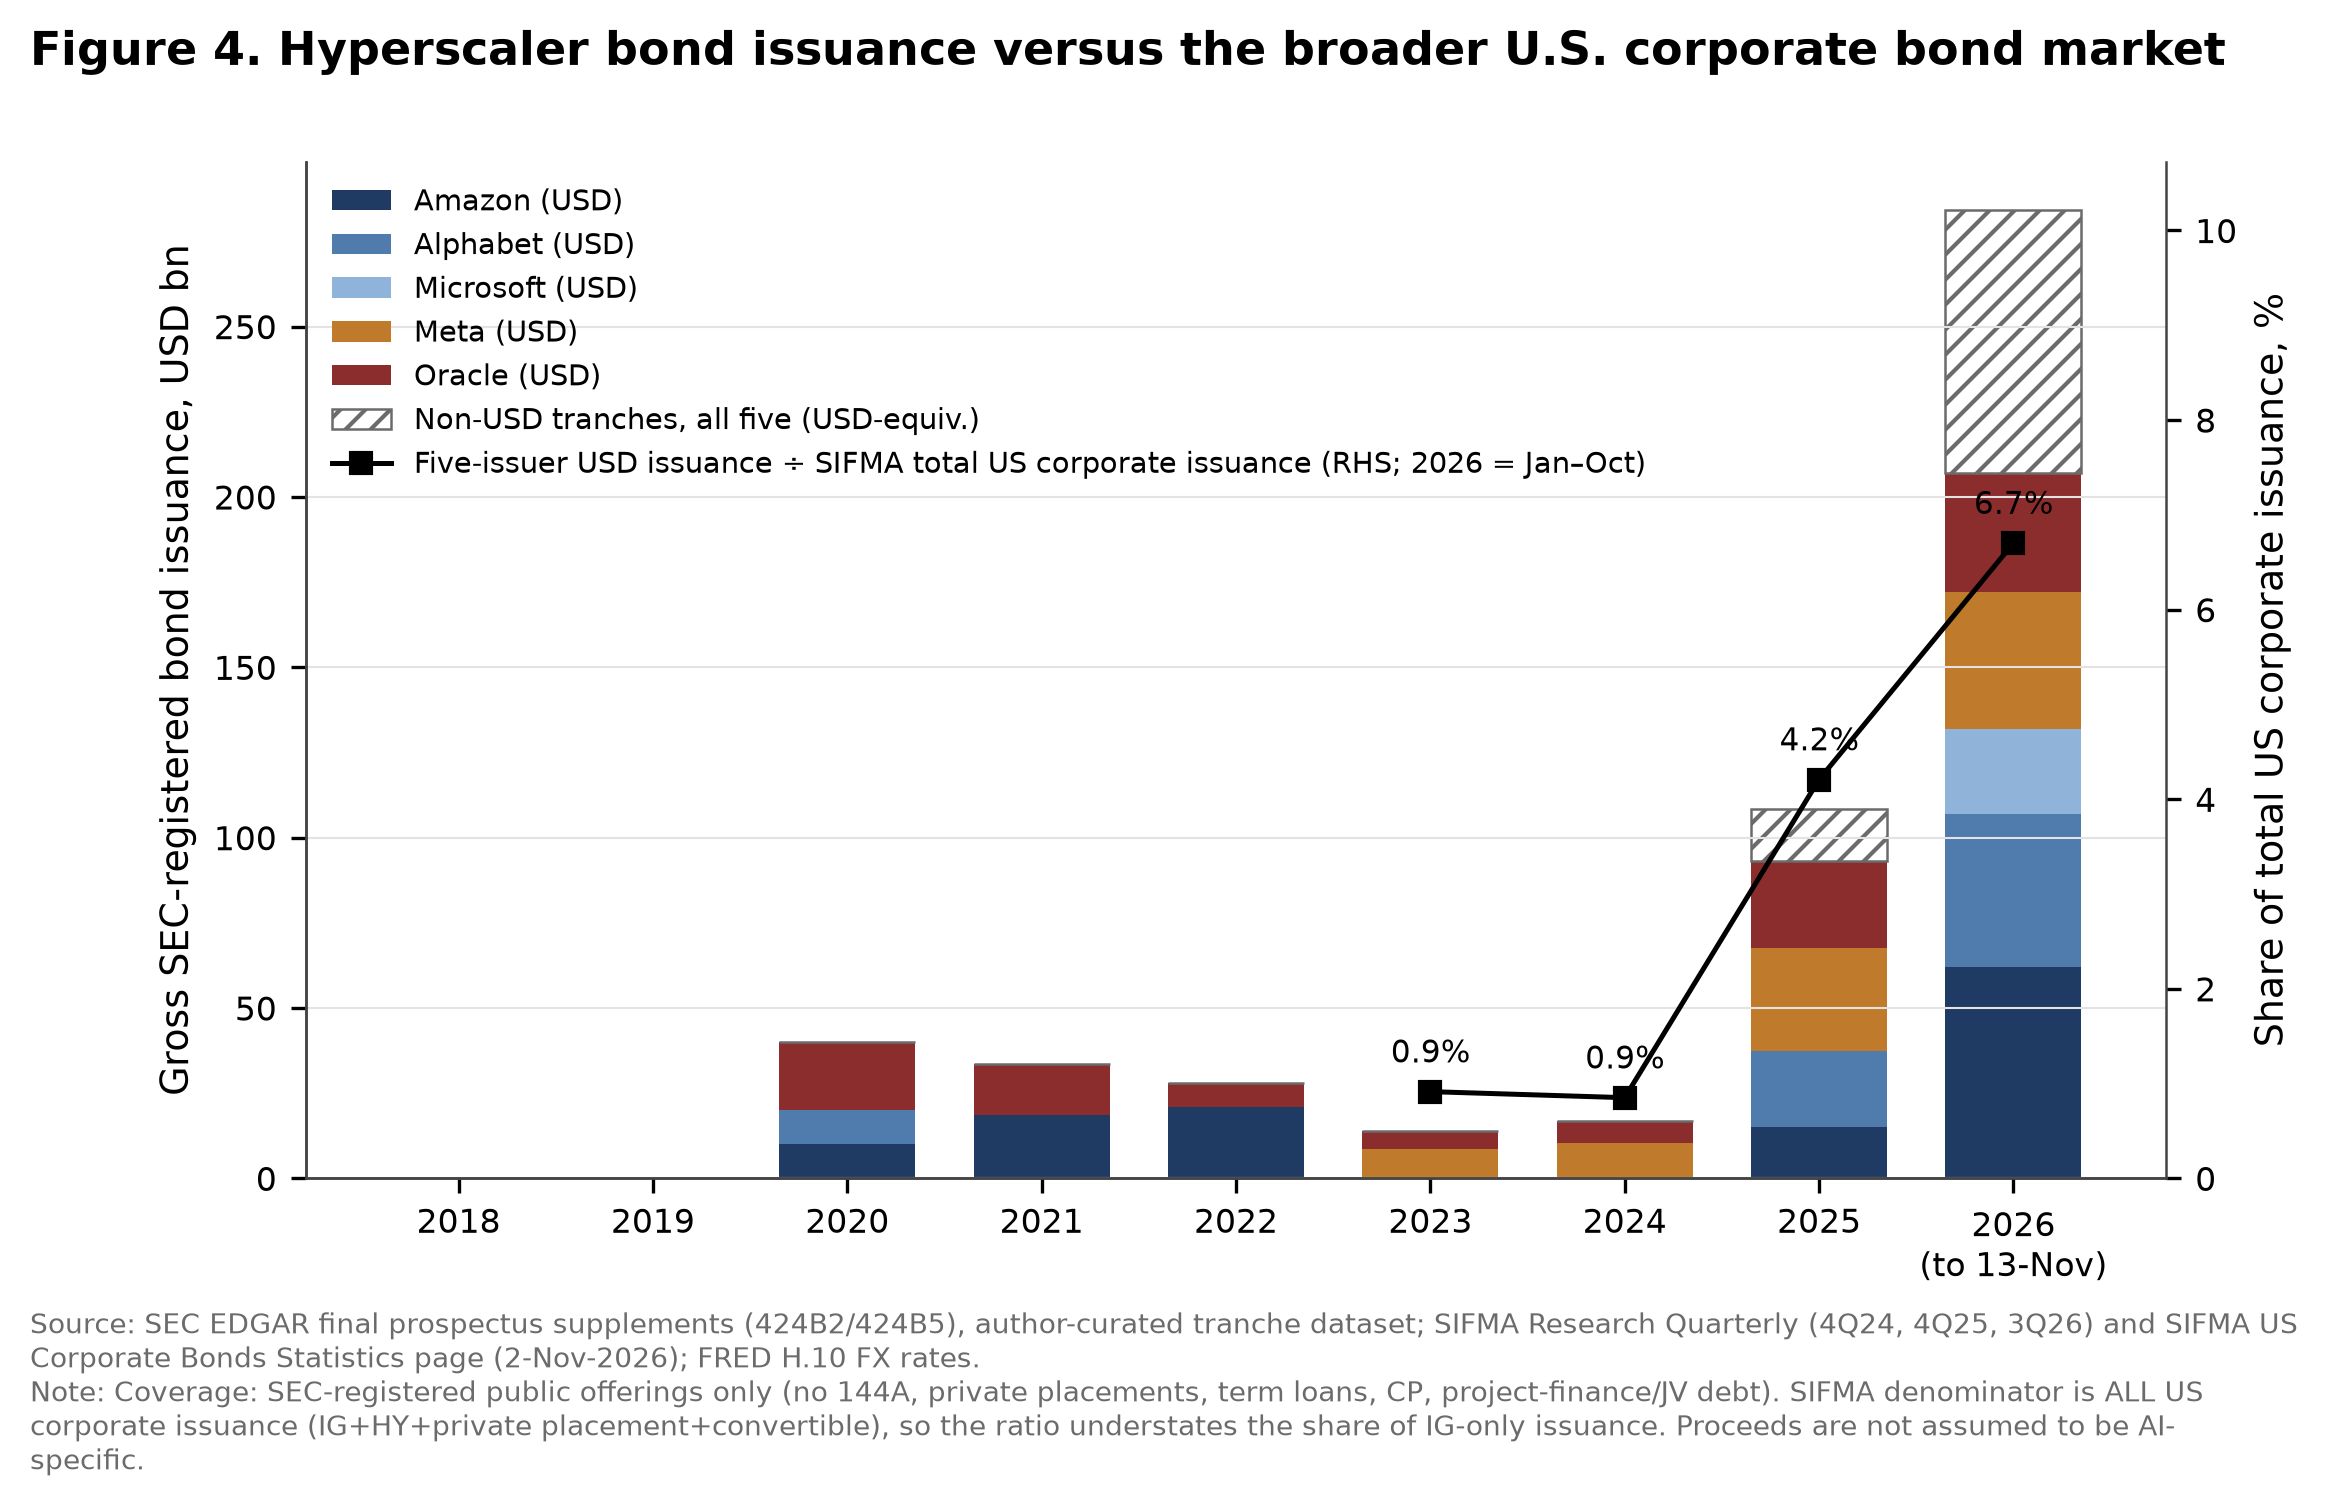

In [3]:
show_md('table_s1_issuance_summary_by_issuer_year'); show_md('table_s2_issuance_concentration_vs_sifma'); show_fig('fig4_issuance_vs_market')

**Table S3. 8–12y new-issue spread vs same-rating ICE OAS**

| ticker | quarter | n | sp_rating | new_issue_spread_bp | rating_index_oas_bp | diff_bp |
|---|---|---|---|---|---|---|
| AMZN | 2025Q4 | 2 | AA | 51.00 | 49.00 | 2.00 |
| AMZN | 2026Q1 | 1 | AA | 75.00 | 56.00 | 19.00 |
| AMZN | 2026Q3 | 1 | AA | 80.00 | 53.00 | 27.00 |
| GOOGL | 2025Q2 | 1 | AA+ | 47.00 | 59.00 | -12.00 |
| GOOGL | 2025Q4 | 1 | AA+ | 62.00 | 49.00 | 13.00 |
| GOOGL | 2026Q1 | 1 | AA+ | 63.00 | 49.00 | 14.00 |
| GOOGL | 2026Q3 | 1 | AA+ | 85.00 | 57.00 | 28.00 |
| META | 2024Q3 | 1 | AA- | 80.00 | 64.00 | 16.00 |
| META | 2025Q4 | 1 | AA- | 78.00 | 47.00 | 31.00 |
| META | 2026Q2 | 1 | AA- | 90.00 | 52.00 | 38.00 |
| META | 2026Q4 | 1 | AA- | 160.0 | 67.00 | 93.00 |
| MSFT | 2026Q4 | 1 | AAA | 65.00 | 70.00 | -5.00 |
| ORCL | 2024Q3 | 1 | BBB | 95.00 | 115.0 | -20.00 |
| ORCL | 2025Q1 | 1 | BBB | 97.00 | 101.0 | -4.00 |
| ORCL | 2025Q3 | 1 | BBB | 105.0 | 95.00 | 10.00 |
| ORCL | 2026Q1 | 1 | BBB | 145.0 | 93.00 | 52.00 |
| ORCL | 2026Q4 | 1 | BBB- | 310.0 | 116.0 | 194.0 |

New-issue spread to benchmark UST from FWP term sheets (validated vs YTM − benchmark). Index OAS: ICE BofA AA/A/BBB on the business day before the final prospectus date. AAA-rated Microsoft mapped to AA bucket. Different spread measures; indicative only.


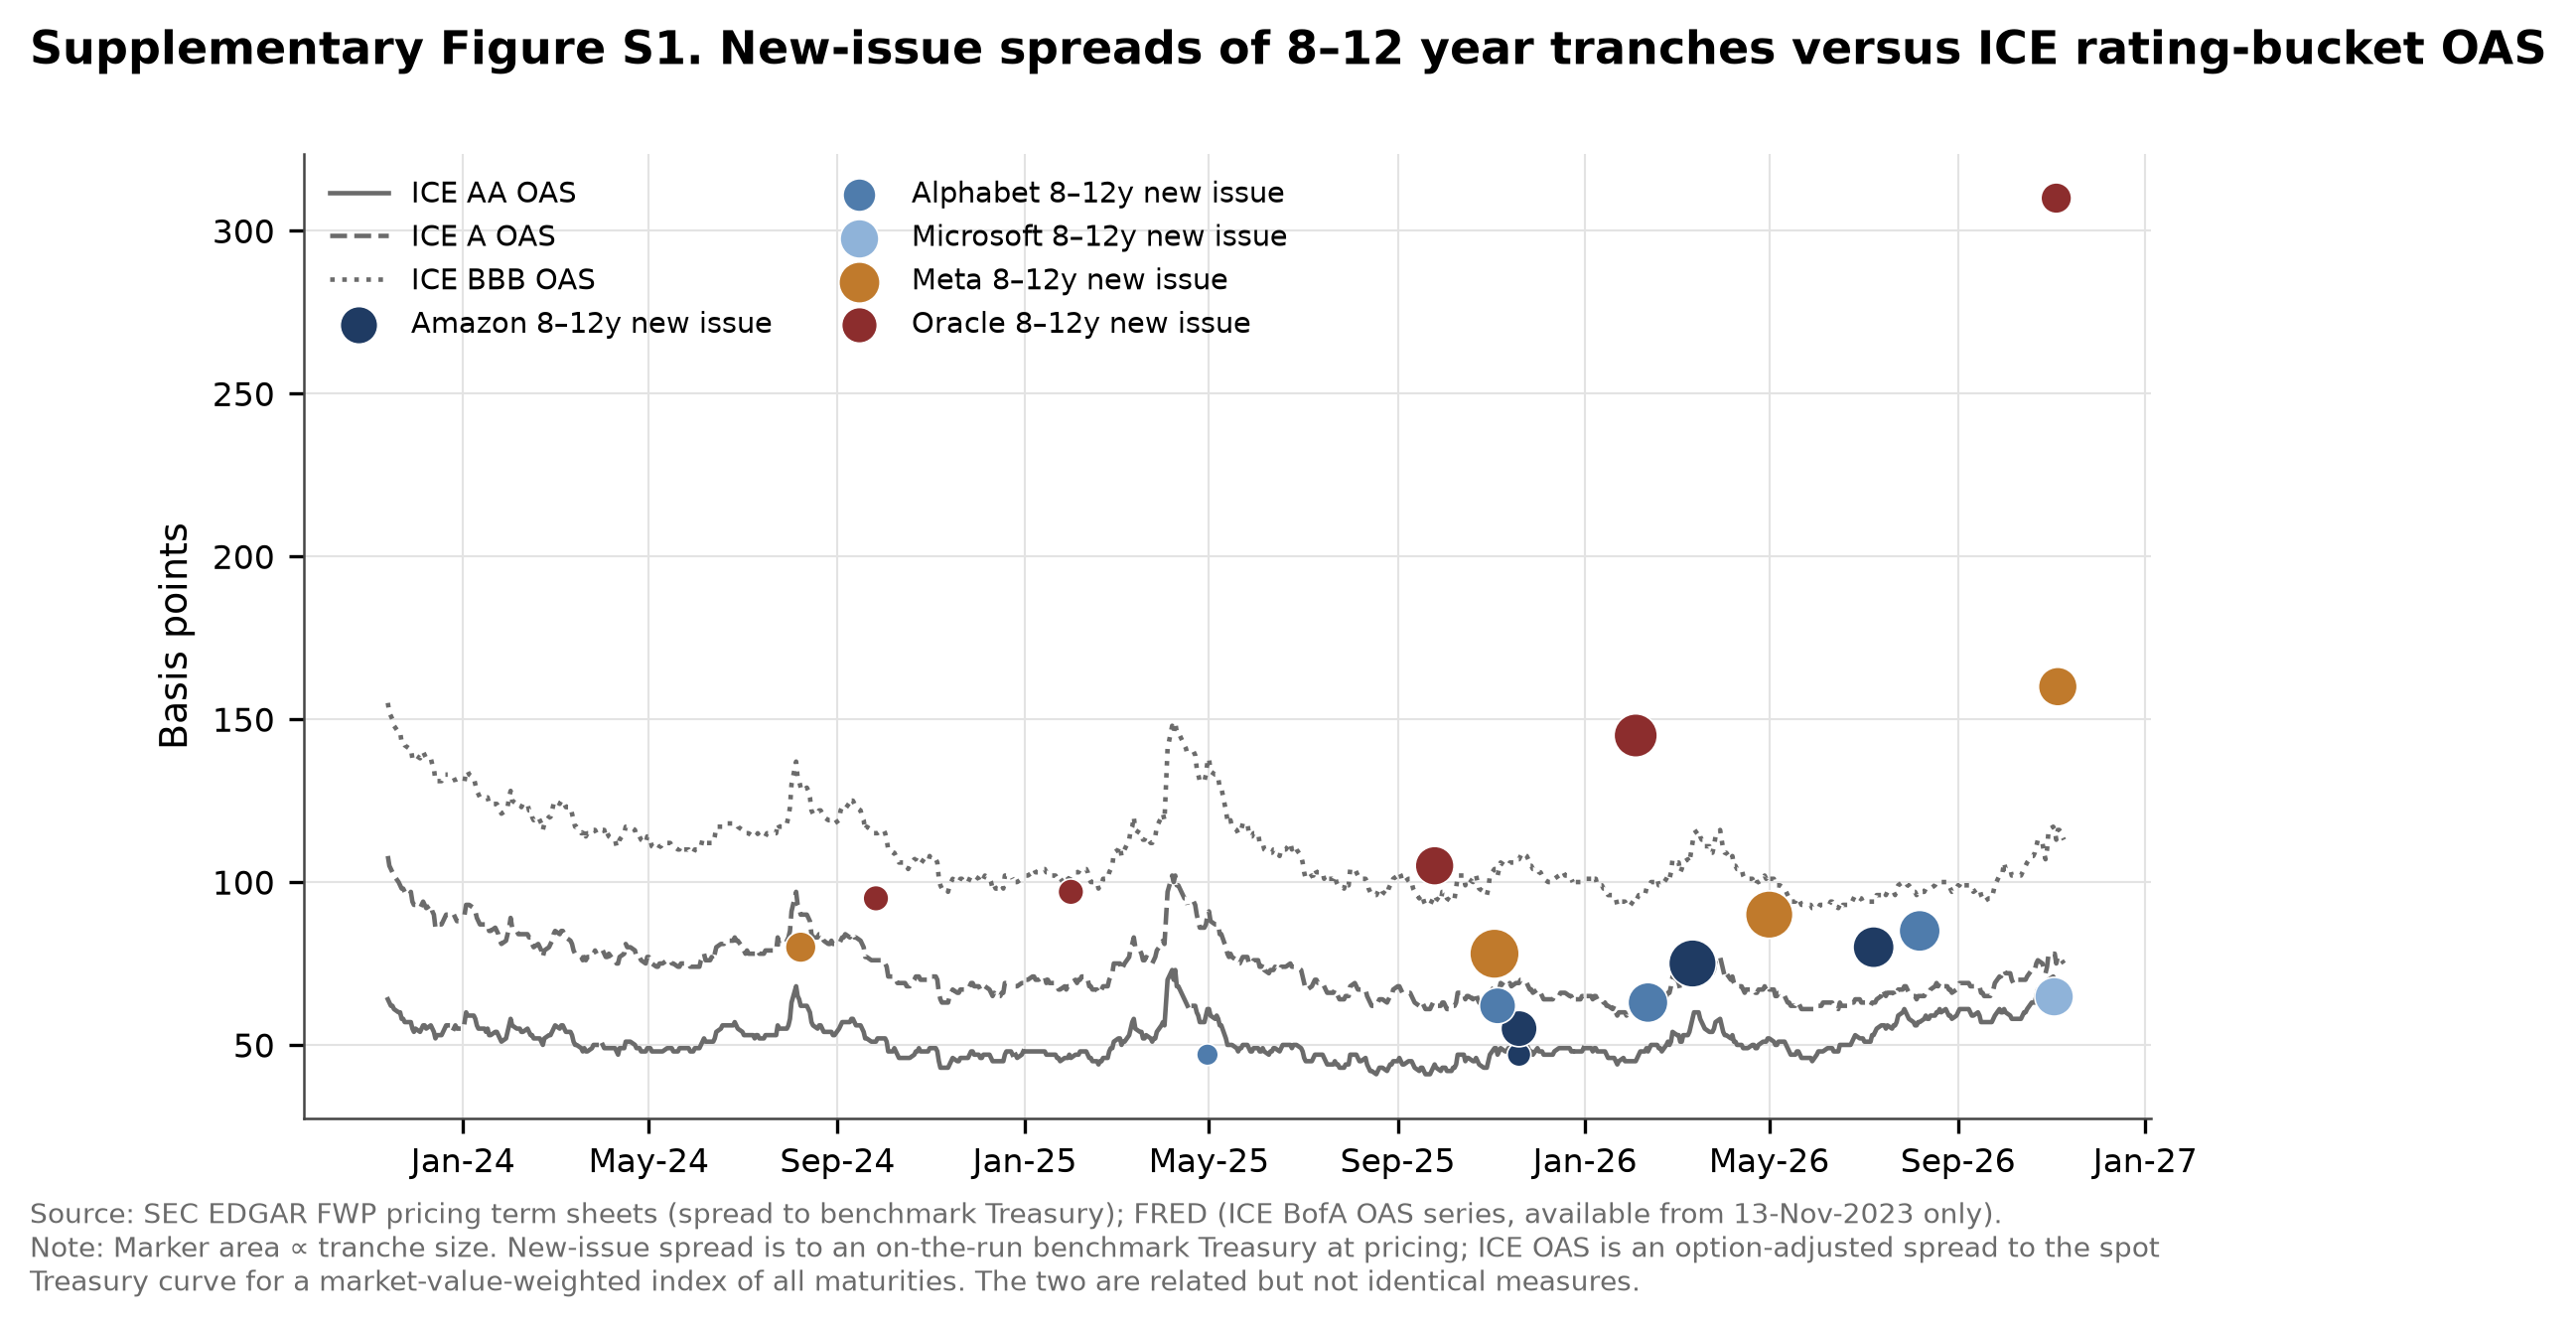

In [4]:
show_md('table_s3_new_issue_spread_vs_ice_oas_8_12y'); show_fig('figS1_new_issue_spreads_vs_index')

In [5]:
show_md('table_s4_new_issue_spread_dv01_2025_2026')

**Table S4. At-issue spread DV01 and DTS of verified 2025–26 USD fixed-rate issues**

| ticker | principal_usd_bn | spread_dv01_usd_mn | pw_mod_duration | pw_spread_bp | pw_dts_at_issue | value_change_spread_+100bp_usd_bn |
|---|---|---|---|---|---|---|
| AMZN | 73.50 | 63.66 | 8.66 | 74.89 | 648.7 | -6.37 |
| GOOGL | 65.75 | 61.30 | 9.32 | 72.32 | 674.3 | -6.13 |
| META | 70.00 | 67.64 | 9.66 | 109.2 | 1,054.8 | -6.76 |
| MSFT | 23.00 | 17.72 | 7.71 | 63.80 | 491.7 | -1.77 |
| ORCL | 59.75 | 49.47 | 8.28 | 153.5 | 1,271.1 | -4.95 |

Par-based; spread duration ≈ modified duration of a bullet bond at the re-offer yield; DTS = duration × spread (years × bp). Covers only verified SEC-registered USD fixed-rate tranches; NOT index-level DTS contribution.


In [6]:
pd.read_csv(ROOT/'data/curated/external_published_statistics.csv')[['stat_id','publisher','publication_date','value','unit','period']]

,stat_id,publisher,publication_date,value,unit,period
0,sifma_corp_iss_2023,SIFMA,2025-01,1503.5,USD bn,FY2023
1,sifma_corp_iss_2024_v2025,SIFMA,2025-01,1957.0,USD bn,FY2024
2,sifma_corp_iss_2024,SIFMA,printed 'January 2025' (apparent misprint; con...,1968.9,USD bn,FY2024
3,sifma_corp_iss_2025,SIFMA,printed 'January 2025' (apparent misprint; con...,2216.3,USD bn,FY2025
4,sifma_corp_iss_2026q1q3,SIFMA,2026-10,2195.1,USD bn,2026 Jan-Sep
5,sifma_corp_iss_3q26,SIFMA,2026-10,649.6,USD bn,3Q26 (Jul-Sep 2026)
6,sifma_corp_ig_share_3q26,SIFMA,2026-10,74.3,percent,3Q26
7,sifma_corp_ig_share_4q25,SIFMA,printed 'January 2025' (apparent misprint; con...,76.0,percent,4Q25
8,sifma_corp_iss_2026ytd_oct,SIFMA,2026-11-02,2342.6,USD bn,2026 Jan-Oct
9,bfin_mv_share,bfinance (Bloomberg index data),2026-10-28,4.85,percent,c. Sep-2026


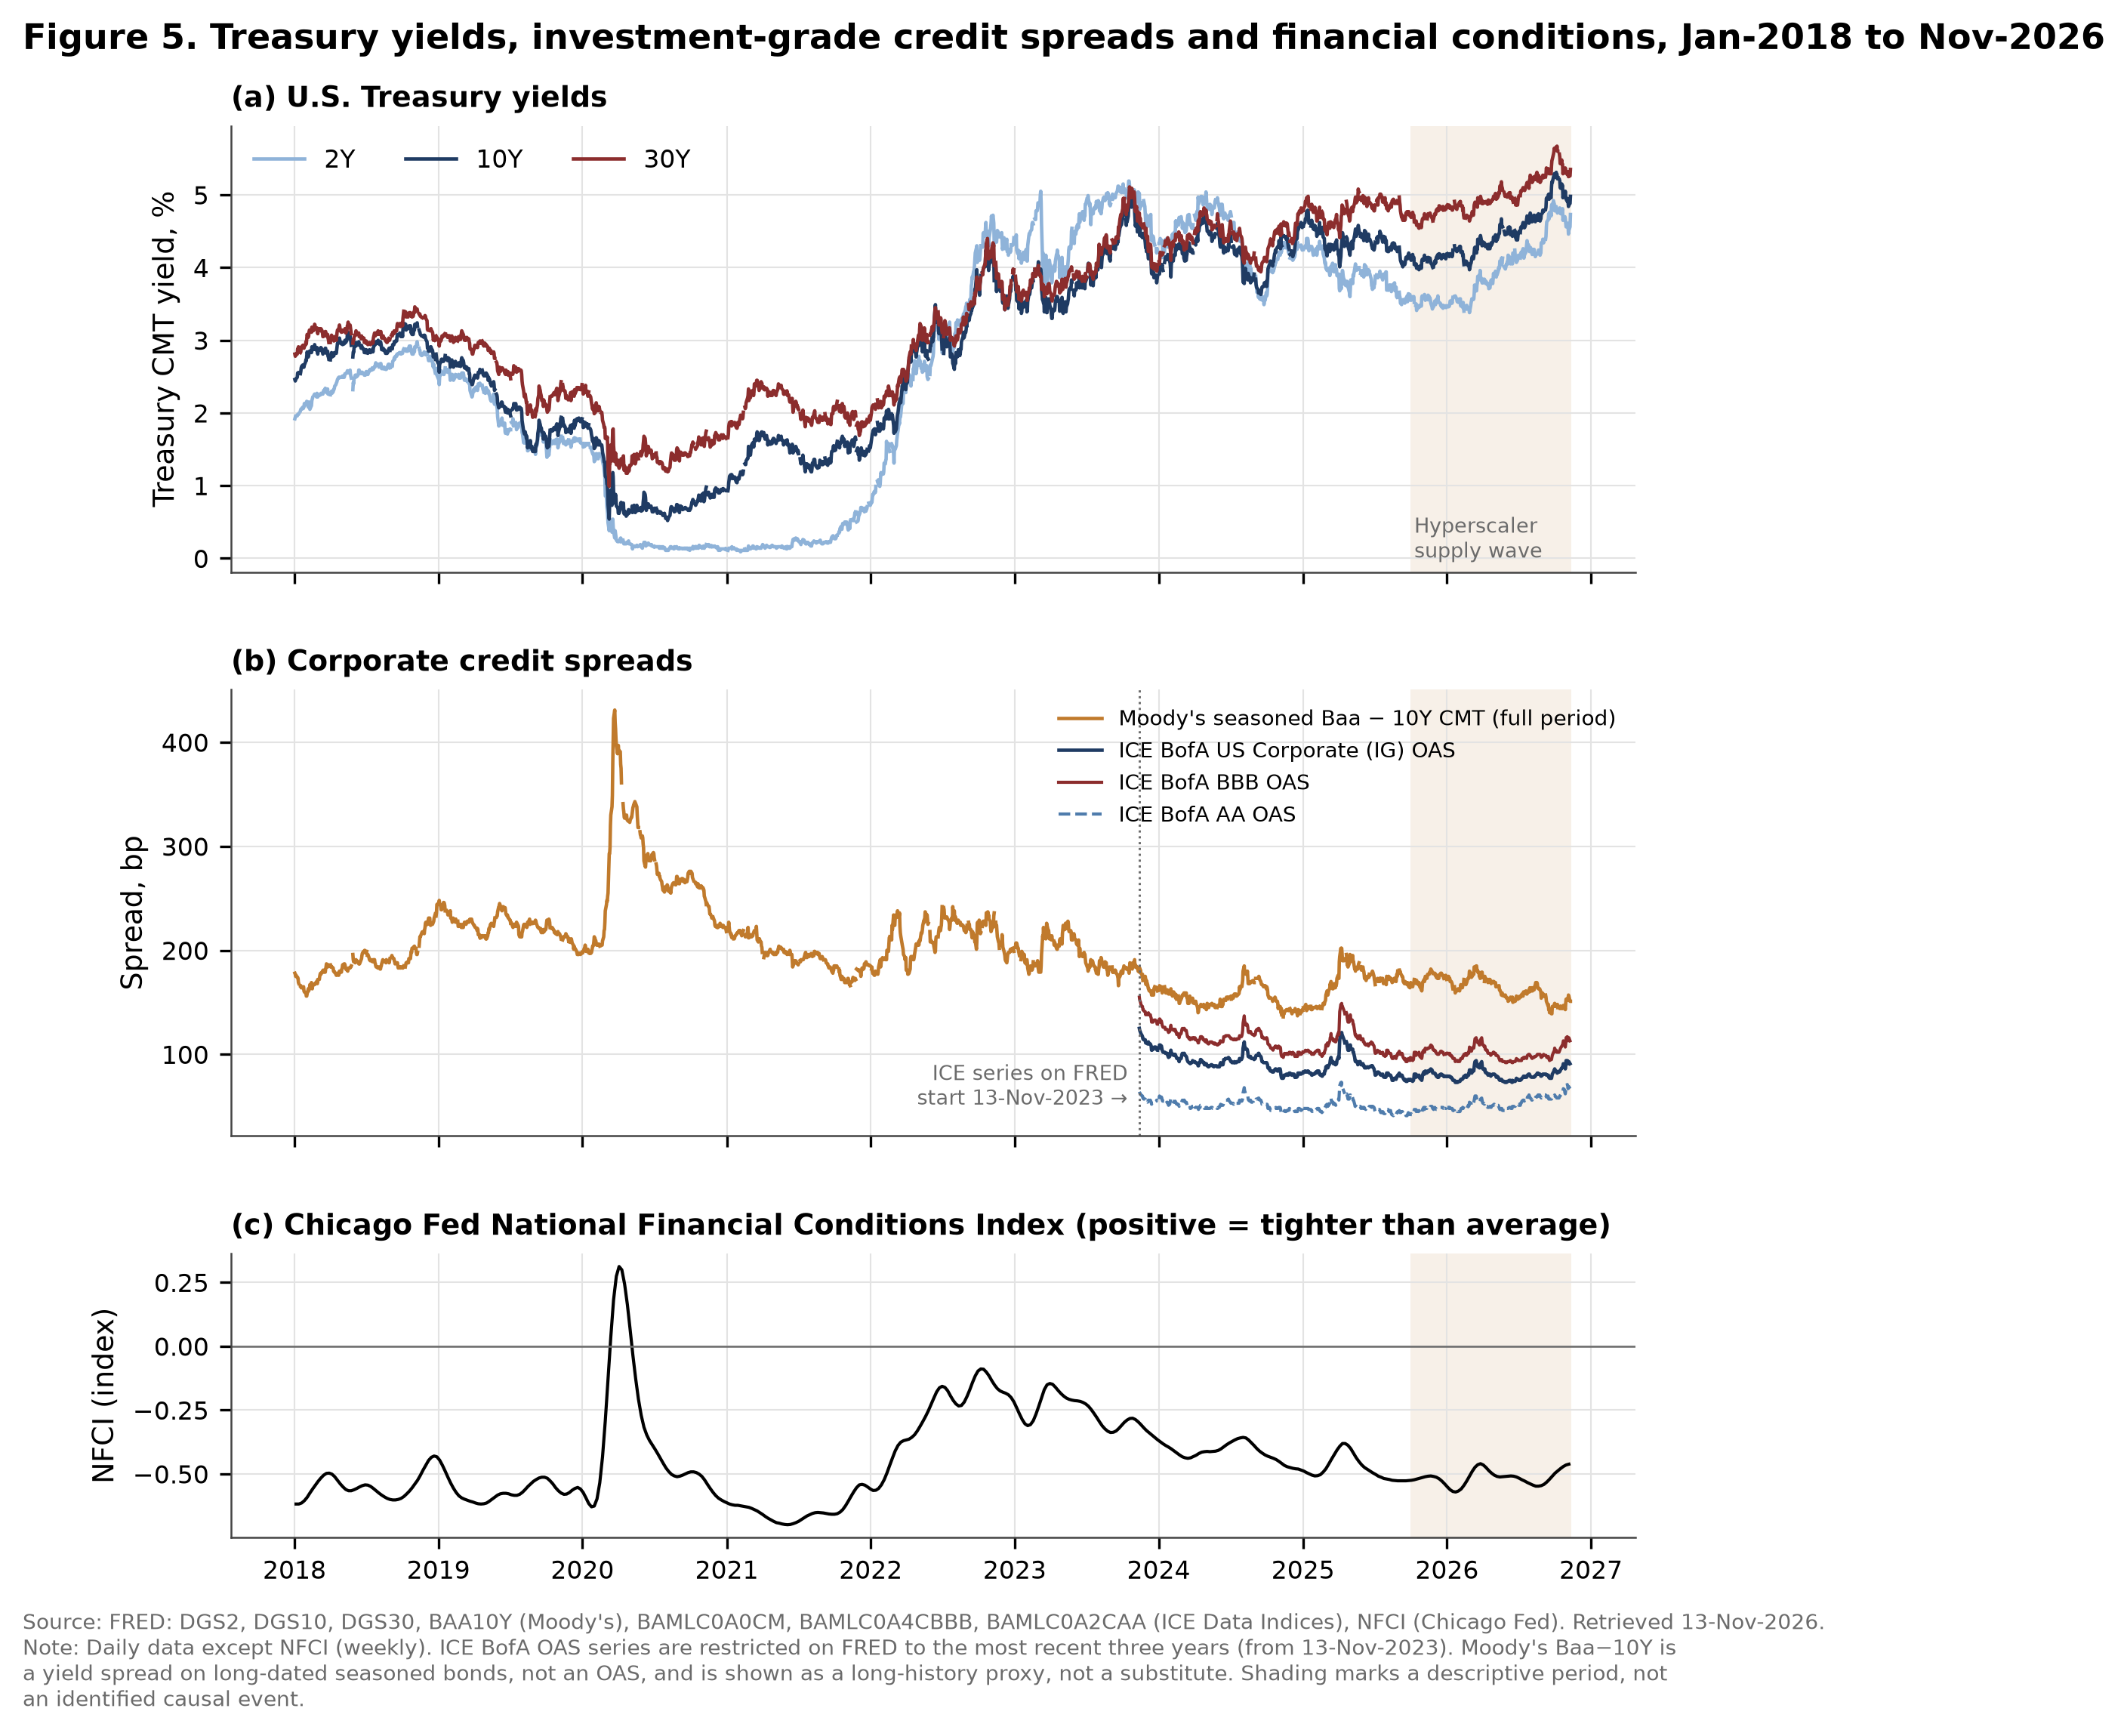

**Table S5. Correlation of Treasury yield changes and credit-spread changes**

| pair | start | end | freq | n | corr_changes | corr_levels |
|---|---|---|---|---|---|---|
| ΔDGS10 vs ΔBAA10Y | 2018-01-02 | 2026-11-10 | D | 2210 | -0.393 | -0.715 |
| ΔDGS10 vs ΔBAA10Y | 2018-01-05 | 2026-11-13 | W-FRI | 462 | -0.255 | -0.713 |
| ΔDGS10 vs ΔBAMLC0A0CM | 2023-11-13 | 2026-11-09 | D | 745 | -0.247 | -0.264 |
| ΔDGS10 vs ΔBAMLC0A0CM | 2023-11-17 | 2026-11-13 | W-FRI | 156 | -0.194 | -0.262 |
| ΔDGS10 vs ΔBAMLC0A0CM | 2025-10-01 | 2026-11-09 | D | 276 | -0.156 | 0.203 |
| ΔDGS10 vs ΔBAMLC0A2CAA | 2025-10-01 | 2026-11-09 | D | 276 | -0.150 | 0.769 |
| ΔDGS30 vs ΔBAMLC0A0CM | 2023-11-13 | 2026-11-09 | D | 745 | -0.201 | -0.526 |

Pearson correlation of first differences (and of levels). Descriptive; no causal interpretation.


**Table S6. Episodes of ≥50bp rise in 10Y UST over 63 business days**

| start | end | d_DGS10_bp | d_BAA10Y_bp | d_BAMLC0A0CM_bp | d_BAMLC0A4CBBB_bp | d_BAMLC0A2CAA_bp |
|---|---|---|---|---|---|---|
| 2020-11-19 | 2021-02-23 | 51.00 | -15.00 |  |  |  |
| 2021-11-05 | 2022-02-08 | 51.00 | 18.00 |  |  |  |
| 2022-02-08 | 2022-05-10 | 103.0 | 25.00 |  |  |  |
| 2022-06-23 | 2022-09-22 | 61.00 | -12.00 |  |  |  |
| 2023-04-04 | 2023-07-05 | 60.00 | -27.00 |  |  |  |
| 2023-07-05 | 2023-10-03 | 86.00 | -1.00 |  |  |  |
| 2024-01-09 | 2024-04-10 | 53.00 | -23.00 | -17.00 | -19.00 | -10.00 |
| 2024-08-02 | 2024-11-01 | 57.00 | -34.00 | -20.00 | -23.00 | -14.00 |
| 2026-02-17 | 2026-05-15 | 54.00 | -8.00 | -5.00 | -7.00 | -3.00 |
| 2026-06-11 | 2026-09-11 | 51.00 | -5.00 | 5.00 | 3.00 | 10.00 |

Non-overlapping windows; concurrent spread changes in bp. NaN where ICE series unavailable (before 13-Nov-2023).


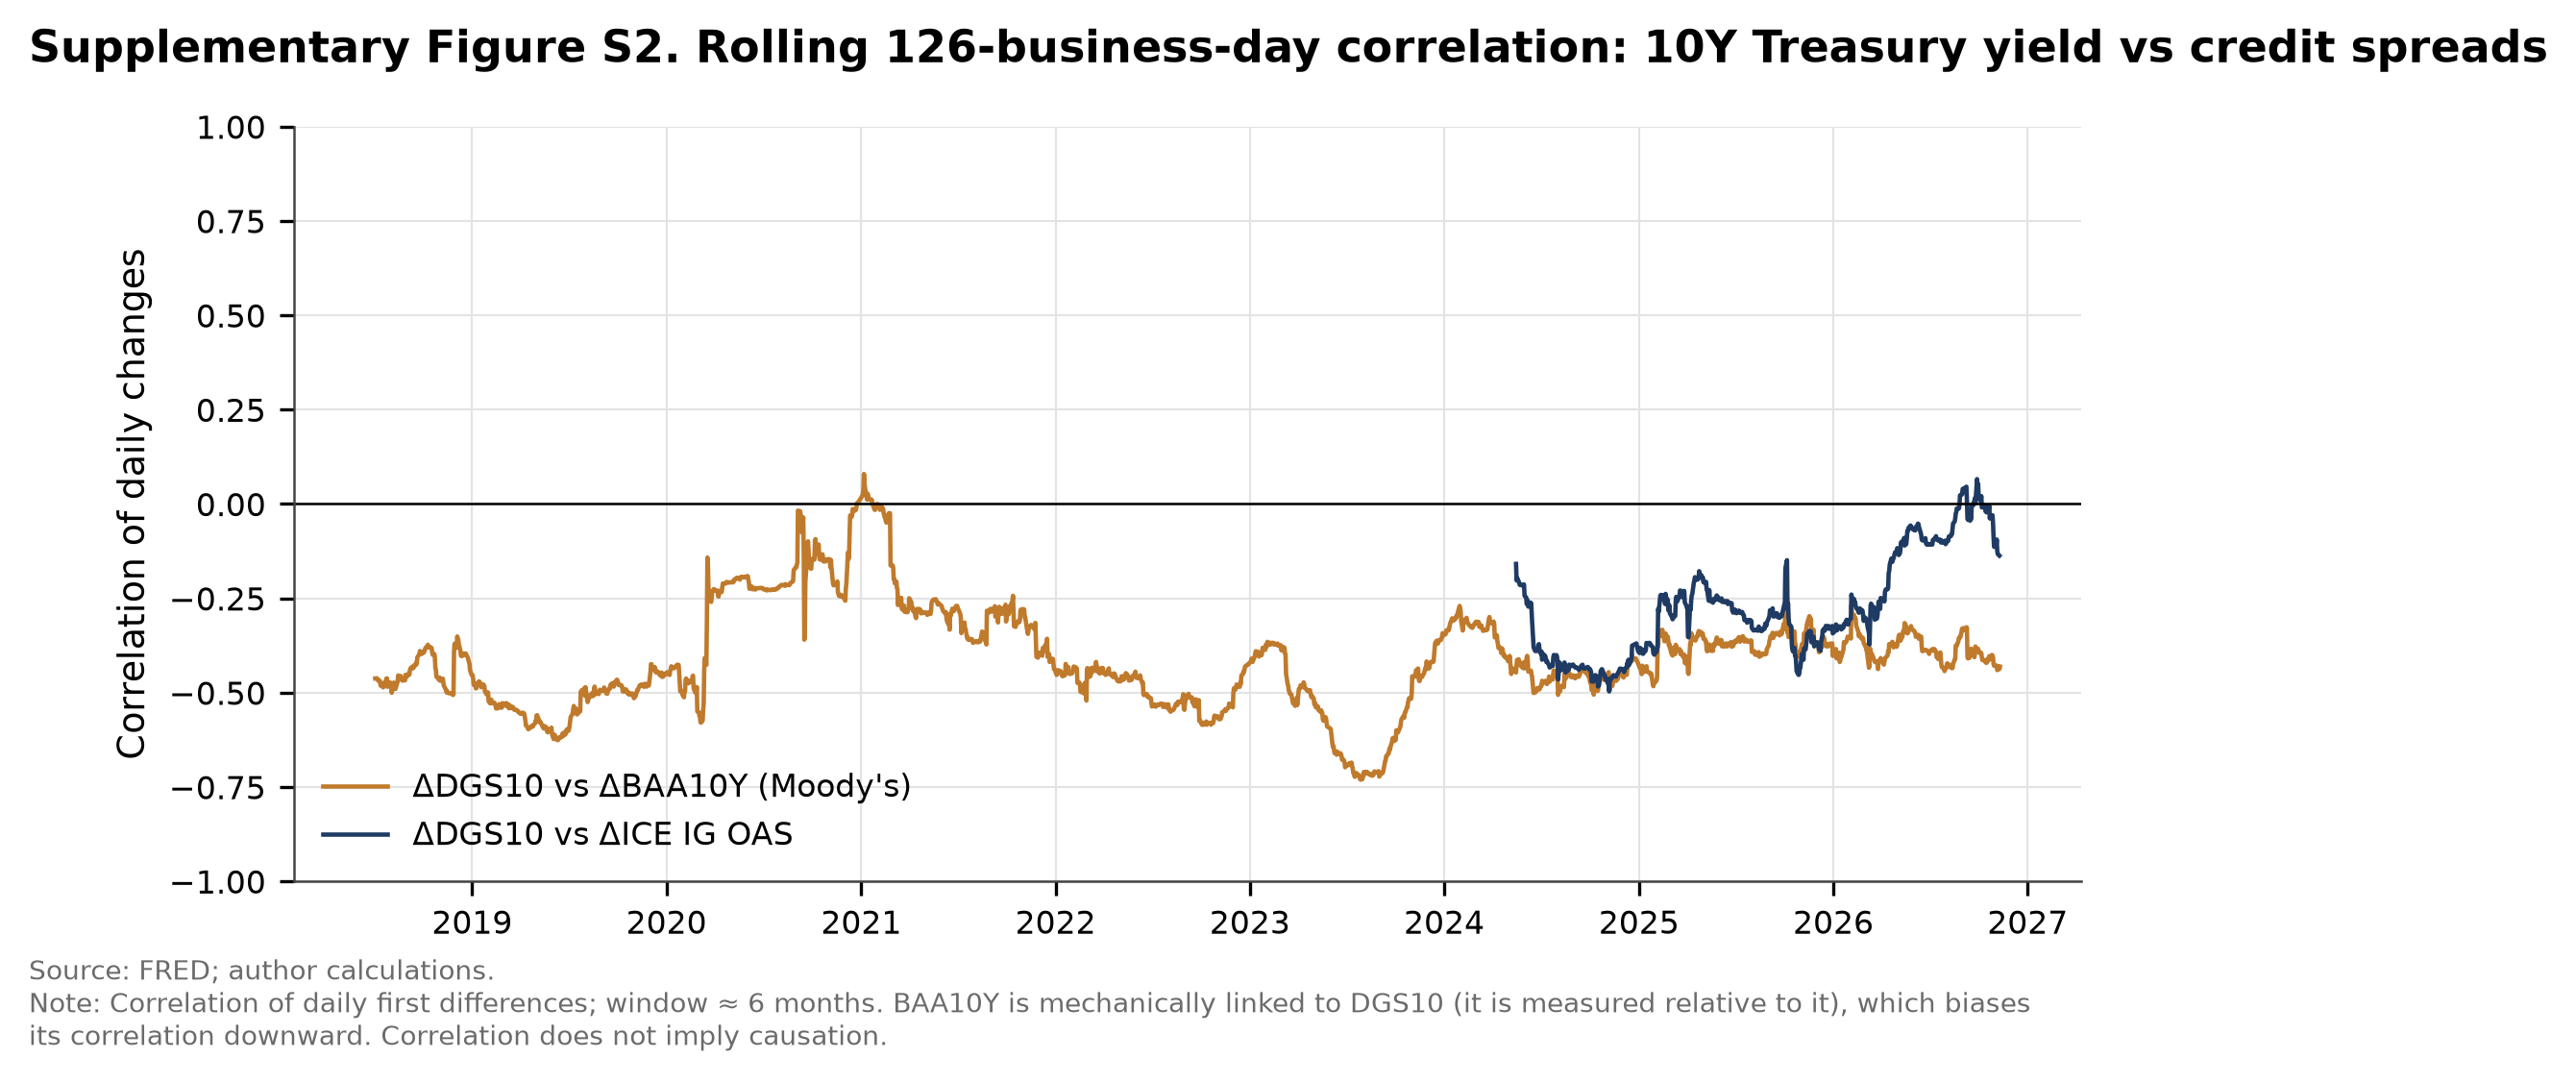

In [7]:
show_fig('fig5_rates_spreads_conditions'); show_md('table_s5_rate_spread_correlations'); show_md('table_s6_10y_rate_shock_episodes'); show_fig('figS2_rolling_correlation')